In [28]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib.pyplot as plt
import pandas as pd

# 修改为自己的学号
STUDENT_ID = 20244080123
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    (f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}").encode()
).hexdigest()[:16]

RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

np.random.seed(42)

[Conda 环境] exp01_env
[学号] 20244080123
[机器指纹] e53a5873cc2d318a
[RUN_ID] 20244080123-e53a5873cc2d318a


===== 实验1：NumPy 数组、数据类型与索引 ======

In [29]:
#====== 1-1 =======
# 创建三种类型数组
arr_int = np.array([1,2,3,4])
arr_float = np.array([1.1,2.2,3.3])
arr_bool = np.array([True, False, True])

print("=====整数数组=====")
print("arr_int:",arr_int)
print("dtype:",arr_int.dtype)
print("shape:",arr_int.shape)
print("ndim:",arr_int.ndim)

print("\n=====浮点数数组=====")
print("arr_float:",arr_float)
print("dtype:",arr_float.dtype)
print("shape:",arr_float.shape)
print("ndim:",arr_float.ndim)

print("\n=====布尔数组=====")
print("arr_bool:",arr_bool)
print("dtype:",arr_bool.dtype)
print("shape:",arr_bool.shape)
print("ndim:",arr_bool.ndim)

=====整数数组=====
arr_int: [1 2 3 4]
dtype: int64
shape: (4,)
ndim: 1

=====浮点数数组=====
arr_float: [1.1 2.2 3.3]
dtype: float64
shape: (3,)
ndim: 1

=====布尔数组=====
arr_bool: [ True False  True]
dtype: bool
shape: (3,)
ndim: 1


**NumPy数组与Python列表区别**
1. Python列表：可以存放任意混合类型元素；存储为对象指针；运算循环Python层，速度慢。
2. NumPy ndarray：**同一种数据类型**；连续内存块存储；向量化运算，C底层实现，运算速度快；自带shape、ndim、dtype属性。

In [30]:
#====== 1-2 =======
a = np.arange(12)
print("原始一维数组 a = np.arange(12):")
print(a)

a1 = a.reshape(3,4)
print("\nreshape(3,4):")
print(a1)

a2 = a.reshape(2,3,2)
print("\nreshape(2,3,2):")
print(a2)

原始一维数组 a = np.arange(12):
[ 0  1  2  3  4  5  6  7  8  9 10 11]

reshape(3,4):
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

reshape(2,3,2):
[[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]


reshape改变形状约束：**新shape所有维度相乘必须等于原数组元素总个数**。
原始数组一共12个元素：
3*4=12，2*3*2=12，所以可以变形；如果乘积不等于12会报ValueError。

In [31]:
#====== 1-3 =======
arr = np.arange(12).reshape(3,4)
print("原数组(3,4):")
print(arr)

# 取第2行
row2 = arr[1,:]
print("\n取第2行 arr[1,:]")
print(row2, "shape =", row2.shape)

# 取第1至第3列
col1_3 = arr[:,1:4]
print("\n取第1~3列 arr[:,1:4]")
print(col1_3, "shape =", col1_3.shape)

# 取大于6的元素
gt6 = arr[arr>6]
print("\n大于6的元素 arr[arr>6]")
print(gt6, "shape =", gt6.shape)

原数组(3,4):
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

取第2行 arr[1,:]
[4 5 6 7] shape = (4,)

取第1~3列 arr[:,1:4]
[[ 1  2  3]
 [ 5  6  7]
 [ 9 10 11]] shape = (3, 3)

大于6的元素 arr[arr>6]
[ 7  8  9 10 11] shape = (5,)


In [32]:
#====== 1-4 =======
x = np.arange(10)
print("x =",x)

# 小于2 或 大于7
res_or1 = x[(x<2) | (x>7)]
res_or2 = x[np.logical_or(x<2, x>7)]
print("\n小于2或大于7（运算符 |）：",res_or1)
print("小于2或大于7（np.logical_or）：",res_or2)

# 大于3 且 小于7
res_and1 = x[(x>3) & (x<7)]
res_and2 = x[np.logical_and(x>3, x<7)]
print("\n大于3且小于7（运算符 &）：",res_and1)
print("大于3且小于7（np.logical_and）：",res_and2)

x = [0 1 2 3 4 5 6 7 8 9]

小于2或大于7（运算符 |）： [0 1 8 9]
小于2或大于7（np.logical_or）： [0 1 8 9]

大于3且小于7（运算符 &）： [4 5 6]
大于3且小于7（np.logical_and）： [4 5 6]


In [33]:
#====== 1-5 =======
A = np.array([[1,2],[3,4]])
B = np.array([[5,6],[7,8]])
print("A:\n",A)
print("B:\n",B)

elem_mul1 = A * B
elem_mul2 = np.multiply(A,B)
mat_mul1 = A @ B
mat_mul2 = np.matmul(A,B)

print("\n逐元素乘法 A * B：\n",elem_mul1)
print("逐元素乘法 np.multiply(A,B)：\n",elem_mul2)
print("\n矩阵乘法 A @ B：\n",mat_mul1)
print("矩阵乘法 np.matmul(A,B)：\n",mat_mul2)

A:
 [[1 2]
 [3 4]]
B:
 [[5 6]
 [7 8]]

逐元素乘法 A * B：
 [[ 5 12]
 [21 32]]
逐元素乘法 np.multiply(A,B)：
 [[ 5 12]
 [21 32]]

矩阵乘法 A @ B：
 [[19 22]
 [43 50]]
矩阵乘法 np.matmul(A,B)：
 [[19 22]
 [43 50]]


1. `*` / `np.multiply()`：**逐元素乘法**，对应位置元素两两相乘，两个数组shape必须完全一样。
2. `@` / `np.matmul()`：**数学矩阵乘法**，遵循矩阵乘法规则，前矩阵列数等于后矩阵行数。

===== 实验2：随机抽样、统计与缺失值 ======

In [34]:
#====== 2-1 =======
scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores,0,100)

n = len(scores)
min_s = np.min(scores)
max_s = np.max(scores)
mean_s = np.mean(scores)
std_s = np.std(scores)
range_s = max_s - min_s

print(f"样本数量：{n}")
print(f"最小值：{min_s:.2f}")
print(f"最大值：{max_s:.2f}")
print(f"均值：{mean_s:.2f}")
print(f"标准差：{std_s:.2f}")
print(f"极差(max‑min)：{range_s:.2f}")

样本数量：1000
最小值：37.59
最大值：100.00
均值：70.18
标准差：9.76
极差(max‑min)：62.41


In [35]:
#====== 2-2 =======
pop = np.arange(1,11)
print("总体pop：",pop)

# 均匀不放回抽样
sample_uniform = np.random.choice(pop,size=5,replace=False)
print("均匀不放回抽样5个：",sample_uniform)

# 按数值大小加权抽样（权重等于元素本身）
p_weight = pop / np.sum(pop)
sample_weighted = np.random.choice(pop,size=5,replace=False,p=p_weight)
print("按数值加权不放回抽样5个：",sample_weighted)

总体pop： [ 1  2  3  4  5  6  7  8  9 10]
均匀不放回抽样5个： [ 4  9  2  6 10]
按数值加权不放回抽样5个： [10  2  8  9  6]


In [36]:
#====== 2-3 =======
arr_ori = np.array([1,2,3,4,5,6,7,8])
print("原始数组：",arr_ori)

# 方式1：返回新数组，原数组不变
arr_shuffle_new = np.random.permutation(arr_ori)
print("\npermutation返回新数组：",arr_shuffle_new)
print("permutation后原数组不变：",arr_ori)

# 方式2：原地打乱 np.random.shuffle
arr_inplace = arr_ori.copy()
np.random.shuffle(arr_inplace)
print("\nshuffle原地打乱结果：",arr_inplace)
print("shuffle不会修改原始arr_ori：",arr_ori)

原始数组： [1 2 3 4 5 6 7 8]

permutation返回新数组： [2 1 7 5 3 8 4 6]
permutation后原数组不变： [1 2 3 4 5 6 7 8]

shuffle原地打乱结果： [3 1 7 5 2 6 8 4]
shuffle不会修改原始arr_ori： [1 2 3 4 5 6 7 8]


1. `np.random.permutation(arr)`：返回打乱后的**新数组**，不会修改输入原数组。
2. `np.random.shuffle(arr)`：**原地in‑place**修改传入数组，无返回值。

In [37]:
#====== 2-4 =======
scores_nan = scores.copy()
# 索引从0开始：第10、20、30个元素对应下标9,19,29
scores_nan[[9,19,29]] = np.nan

mean_normal = np.mean(scores_nan)
mean_nan_safe = np.nanmean(scores_nan)
nan_count = np.sum(np.isnan(scores_nan))

print(f"含nan数组普通np.mean：{mean_normal}")
print(f"忽略nan np.nanmean：{mean_nan_safe:.2f}")
print(f"缺失值nan总个数：{nan_count}")

含nan数组普通np.mean：nan
忽略nan np.nanmean：70.20
缺失值nan总个数：3


普通`np.mean()`只要数组包含任意`np.nan`，输出直接得到`nan`，无法计算有效数据；
必须使用nan安全版本函数`np.nanmean / np.nanmin / np.nanmax`，自动跳过缺失值计算。

In [38]:
#====== 2-5 =======
idx_arr = np.arange(len(scores_nan))
# 内存表格，不保存文件
df_scores_memory = pd.DataFrame({"index":idx_arr, "score":scores_nan})
print("内存表格前8行：")
print(df_scores_memory.head(8))

内存表格前8行：
   index      score
0      0  74.967142
1      1  68.617357
2      2  76.476885
3      3  85.230299
4      4  67.658466
5      5  67.658630
6      6  85.792128
7      7  77.674347


===== 实验3：SciPy 数值计算与 Matplotlib 可视化 ======

In [40]:
#======= 3-1 =======
from scipy.linalg import solve

A = np.array([[3,1],
              [1,2]])
b = np.array([9,8])

x_sol = solve(A,b)
print("方程组解 x,y =",x_sol)

# numpy代入验证
x_val,y_val = x_sol
eq1 = 3*x_val + y_val
eq2 = x_val + 2*y_val
print(f"代入验证：3x+y = {eq1}, x+2y = {eq2}")

方程组解 x,y = [2. 3.]
代入验证：3x+y = 9.0, x+2y = 8.0


In [41]:
#====== 3-2 =======
from scipy.optimize import root

def f(x):
    return x**2 - 2

# 初值 2 求正根
res_pos = root(f, x0=2)
# 初值 -2 求负根
res_neg = root(f, x0=-2)

print("====初值x0=2 求正根====")
print("求解成功flag：",res_pos.success)
print("根：",res_pos.x)
print("函数值f(x):",f(res_pos.x))

print("\n====初值x0=-2 求负根====")
print("求解成功flag：",res_neg.success)
print("根：",res_neg.x)
print("函数值f(x):",f(res_neg.x))

====初值x0=2 求正根====
求解成功flag： True
根： [1.41421356]
函数值f(x): [8.8817842e-16]

====初值x0=-2 求负根====
求解成功flag： True
根： [-1.41421356]
函数值f(x): [8.8817842e-16]


In [42]:
#====== 3-3 =======
from scipy.optimize import minimize

def func(x):
    return x**2 + x + 2

res_min = minimize(func, x0=0)
print("minimize求解成功：",res_min.success)
print("极小点 x =", res_min.x)
print("极小函数值 f(x) =", res_min.fun)
print("\n解析解：x = -0.5，f(-0.5)=1.75")

minimize求解成功： True
极小点 x = [-0.50000001]
极小函数值 f(x) = 1.75

解析解：x = -0.5，f(-0.5)=1.75


In [43]:
#====== 3-4 =======
from scipy.stats import ttest_ind

s1 = np.random.normal(loc=0, scale=1, size=100)
s2 = np.random.normal(loc=1, scale=1, size=100)

t_stat, p_val = ttest_ind(s1, s2)
print(f"t统计量 = {t_stat:.3f}")
print(f"p‑value = {p_val:.4f}")
alpha = 0.05
if p_val < alpha:
    print(f"p < {alpha}，拒绝原假设，两组均值存在显著差异")
else:
    print(f"p >= {alpha}，不能拒绝原假设，无充分证据说明均值有差异")

t统计量 = -6.668
p‑value = 0.0000
p < 0.05，拒绝原假设，两组均值存在显著差异


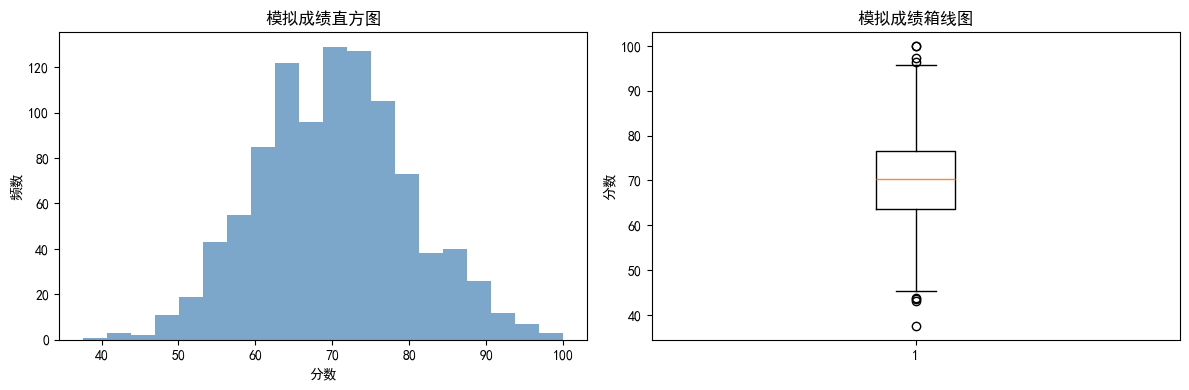

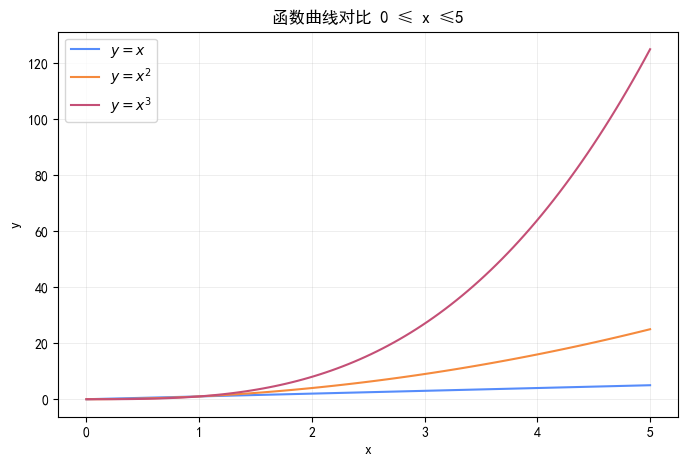

In [44]:
#====== 3-5 =======
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 图1：直方图 & 箱线图，2个子图
valid_score = scores_nan[~np.isnan(scores_nan)]
fig,(ax1,ax2) = plt.subplots(1,2,figsize=(12,4))

ax1.hist(valid_score,bins=20,color="steelblue",alpha=0.7)
ax1.set_title("模拟成绩直方图")
ax1.set_xlabel("分数")
ax1.set_ylabel("频数")

ax2.boxplot(valid_score)
ax2.set_title("模拟成绩箱线图")
ax2.set_ylabel("分数")
plt.tight_layout()
plt.show()

# 图2 同一坐标系 y=x, y=x², y=x³
x = np.linspace(0,5,100)
y1 = x
y2 = x**2
y3 = x**3
plt.figure(figsize=(8,5))
plt.plot(x,y1,label="$y=x$")
plt.plot(x,y2,label="$y=x^2$")
plt.plot(x,y3,label="$y=x^3$")
plt.title("函数曲线对比 0 ≤ x ≤5")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

===== 实验4：pandas Series、DataFrame 与内存中的
CSV 读写 ======

In [45]:
#====== 4-1 =======
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pd.DataFrame(records)
df = df.set_index("Name")

# 新增总分、平均分
df["Total"] = df["Math"] + df["English"] + df["Python"]
df["Average"] = df["Total"] / 3

print("行索引：",df.index.tolist())
print("\n列名：",df.columns.tolist())
print("\n前3行：")
print(df.head(3))
print("\n基本统计信息：")
print(df.describe())

行索引： ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']

列名： ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前3行：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计信息：
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


In [46]:
#====== 4-2 =======
# loc按标签索引
row_carol_loc = df.loc["Carol"]
print("loc['Carol']:\n",row_carol_loc)

# iloc按位置索引，Carol是第2行（下标1）
row_carol_iloc = df.iloc[1]
print("\niloc[1]:\n",row_carol_iloc)

# 筛选平均分>=80
df_high = df[df["Average"] >= 80]
print("\n平均分>=80学生：")
print(df_high)

loc['Carol']:
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

iloc[1]:
 Group              A
Math              72
English           68
Python            80
Total            220
Average    73.333333
Name: Bob, dtype: object

平均分>=80学生：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


In [48]:
#======= 4-3 =======
col_mean = df.mean(axis=0, numeric_only=True)
print("axis=0 每一列（科目）均值：")
print(col_mean)

row_mean = df.mean(axis=1, numeric_only=True)
print("\naxis=1 每行（每个学生）均值：")
print(row_mean)

axis=0 每一列（科目）均值：
Math        79.833333
English     80.833333
Python      83.666667
Total      244.333333
Average     81.444444
dtype: float64

axis=1 每行（每个学生）均值：
Name
Alice    127.400000
Bob      102.666667
Carol    123.666667
David     97.066667
Eva      119.933333
Frank    113.400000
dtype: float64


In [49]:
#====== 4-4 =======
# apply：每行取三科最高分
df["MaxSub"] = df[["Math","English","Python"]].apply(max, axis=1)
print("增加MaxSub(单科最高分):")
print(df[["Math","English","Python","MaxSub"]])

# agg 每科同时得到min mean max
stat_agg = df[["Math","English","Python"]].agg(["min","mean","max"])
print("\nagg聚合每科min/mean/max：")
print(stat_agg)

# rank按Average排名，数值越大名次越前
df["Rank"] = df["Average"].rank(ascending=False)
print("\n按平均分排名Rank：")
print(df[["Average","Rank"]])

增加MaxSub(单科最高分):
       Math  English  Python  MaxSub
Name                                
Alice    88       90      95      95
Bob      72       68      80      80
Carol    91       85      89      91
David    65       73      70      73
Eva      79       92      86      92
Frank    84       77      82      84

agg聚合每科min/mean/max：
           Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000

按平均分排名Rank：
         Average  Rank
Name                  
Alice  91.000000   1.0
Bob    73.333333   5.0
Carol  88.333333   2.0
David  69.333333   6.0
Eva    85.666667   3.0
Frank  81.000000   4.0


In [50]:
#====== 4-5 =======
gp = df.groupby("Group")
print("每组人数：")
print(gp.size())

print("\n每组三科平均分：")
print(gp[["Math","English","Python"]].mean())

# transform，给每行添加本组Python平均分
df["Group_Python_Mean"] = gp["Python"].transform("mean")
print("\n增加组内Python平均分列：")
print(df[["Group","Python","Group_Python_Mean"]])

每组人数：
Group
A    3
B    3
dtype: int64

每组三科平均分：
            Math    English     Python
Group                                 
A      79.666667  83.333333  87.000000
B      80.000000  78.333333  80.333333

增加组内Python平均分列：
      Group  Python  Group_Python_Mean
Name                                  
Alice     A      95          87.000000
Bob       A      80          87.000000
Carol     B      89          80.333333
David     B      70          80.333333
Eva       A      86          87.000000
Frank     B      82          80.333333


In [51]:
#====== 4-6 =======
# filter过滤分组：该组Python组平均分>=80
df_filtered = gp.filter(lambda g: g["Python"].mean() >=80)
print("Python组平均分>=80的分组对应的学生：")
print(df_filtered)

Python组平均分>=80的分组对应的学生：
      Group  Math  English  Python  Total    Average  MaxSub  Rank  \
Name                                                                 
Alice     A    88       90      95    273  91.000000      95   1.0   
Bob       A    72       68      80    220  73.333333      80   5.0   
Carol     B    91       85      89    265  88.333333      91   2.0   
David     B    65       73      70    208  69.333333      73   6.0   
Eva       A    79       92      86    257  85.666667      92   3.0   
Frank     B    84       77      82    243  81.000000      84   4.0   

       Group_Python_Mean  
Name                      
Alice          87.000000  
Bob            87.000000  
Carol          80.333333  
David          80.333333  
Eva            87.000000  
Frank          80.333333  


In [52]:
#====== 4-7 =======
score_cols = ["Math","English","Python"]
cov_mat = df[score_cols].cov()
corr_mat = df[score_cols].corr()

print("协方差矩阵：")
print(cov_mat)
print("\n皮尔逊相关系数矩阵：")
print(corr_mat)

协方差矩阵：
              Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667

皮尔逊相关系数矩阵：
             Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000


**协方差、相关系数含义示例（例如Math与Python）**
1. 协方差：符号代表变化趋势；正数代表两门科目成绩大体同向变化；负数反向。协方差受数据量级影响，大小不能直接比较强弱。
2. 皮尔逊相关系数：取值 [-1, 1]。
- 接近 +1：强正相关；
- 接近 0：几乎无线性相关；
- 接近‑1：强负相关。